In [1]:
import pandas as pd 
df1 = pd.read_csv('data/prices_round_3_day_1.csv')
df2 = pd.read_csv('data/prices_round_3_day_2.csv')
df3 = pd.read_csv('data/prices_round_3_day_0.csv')

In [2]:
df1['product'].value_counts()

product
VELVETFRUIT_EXTRACT    10000
HYDROGEL_PACK          10000
VEV_6000               10000
VEV_5000               10000
VEV_6500               10000
VEV_5300               10000
VEV_5400               10000
VEV_4000               10000
VEV_5100               10000
VEV_5200               10000
VEV_5500               10000
VEV_4500               10000
Name: count, dtype: int64

9999.9183
9999.9183


<Axes: >

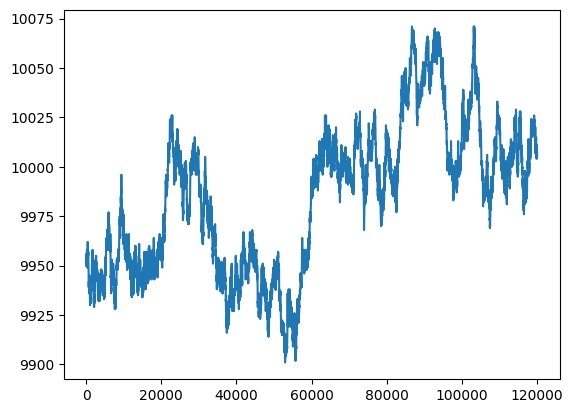

In [3]:
vel_df = df1[df1['product'] == 'HYDROGEL_PACK']
print(vel_df['ask_price_1'].mean())
print(vel_df['ask_price_1'].mean())
vel_df['bid_price_1'].plot()

15.7264


<Axes: >

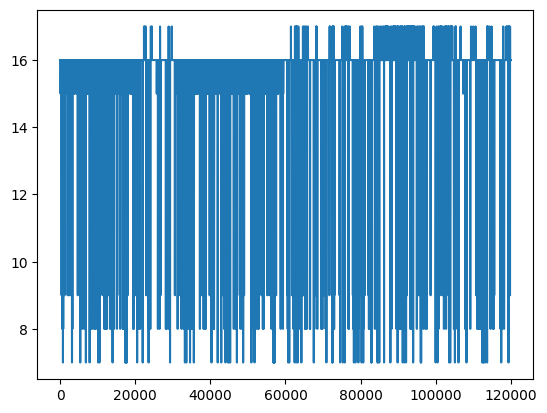

In [4]:
spread = vel_df['ask_price_1'] - vel_df['bid_price_1']
print(spread.mean())
spread.plot()

## Curated HYDROGEL_PACK backtests (BBO-consistent PnL)

- **MTM (mark-to-mark)**: per bar, `pos[t] * (mid[t] - mid[t-1])` (same bar convention as the original EMA cell).
- **Taker execution costs** on each `Δpos` (taker / crossing spread at BBO): **buys** pay `ask`, **sells** hit `bid`, vs marking at `mid`:
  - `taker_leg = max(0, Δpos) * (ask - mid) + max(0, -Δpos) * (mid - bid)`
  - For this data, `mid` equals `(bid_1 + ask_1) / 2` exactly, so that equals `|Δpos| * (half-spread)` but we keep the **explicit** bid/ask form for correctness if data change.
- **EMA**: golden/death cross, ±`POS_LIMIT`.
- **Band MR**: hysteresis around 10,000; same taker model.
- **MM proxy (simplified)**: small mean-reversion **inventory** vs 10k (coarse steps) — **not** a full `StaticTrader` / book replay. Two friction modes: `taker` and **maker-style** = same legs × `MM_MAKER_FRACTION` of the taker one-way (proxy for making vs crossing).
- **Hybrid**: in a band around 10k, follow the **MM proxy**; outside, follow **EMA** (regime + inventory idea without a second EMA).


In [ ]:
# === Curated backtests: EMA, band MR, MM proxy, hybrid (BBO-consistent taker PnL) ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- data & config (single day: df1; change to pd.concat for multi-day) ---
PRODUCT = "HYDROGEL_PACK"
POS_LIMIT = 200
FAST_SPAN, SLOW_SPAN = 50, 100
BAND = 40.0
ANCHOR = 10_000.0
# Hybrid: |mid-10k| < this in price (same units as mid) => use MM proxy; else EMA
HYBRID_INNER = 30.0
# MM proxy: coarser steps => fewer rebalances; tune STEP and LOT
MM_STEP = 30.0
MM_LOT = 15
MM_LAYERS = 6  # |target| in lots capped at LAYERS * MM_LOT
# Maker cost proxy (fraction of taker one-way) only for the MM and hybrid-while-inner legs if you set USE_MAKER_MM
MM_MAKER_FRACTION = 0.15
USE_MAKER_FRICTION_ON_MM = True  # if False, MM proxy also uses full taker costs

bt_df = df1[df1["product"] == PRODUCT].copy().reset_index(drop=True)
n = len(bt_df)
mid = bt_df["mid_price"].astype(float)
bid = bt_df["bid_price_1"].astype(float)
ask = bt_df["ask_price_1"].astype(float)
bbo_mid = (bid + ask) / 2.0
if not bool(np.isfinite(mid.values).all()):
    raise ValueError("non-finite mid")
max_mid_err = float((mid - bbo_mid).abs().max())
if max_mid_err > 1e-3:
    print("Warning: max |mid - (bid+ask)/2| =", max_mid_err, "— taker and symmetric will diverge more.")
spread = (ask - bid).clip(lower=0)
half_spread = spread / 2.0
ret = mid.diff().fillna(0.0)


def taker_leg_dpos(dpos, midv, bidv, askv):
    """Per-bar taker (crossing) cost vs mid if you execute Δpos in one bar at BBO: buy at ask, sell at bid."""
    buy = np.maximum(dpos, 0.0)
    sell = np.maximum(-dpos, 0.0)  # units sold
    return buy * (askv - midv) + sell * (midv - bidv)


def backtest_pnl(
    name,
    position: np.ndarray,
    friction_mode: str,  # "taker" | "maker" where maker = taker * MM_MAKER_FRACTION
):
    dpos = np.diff(position, prepend=0)
    pnl_mtm = position * ret.to_numpy()
    taker_leg = taker_leg_dpos(dpos, mid.to_numpy(), bid.to_numpy(), ask.to_numpy())
    if friction_mode == "taker":
        fr = taker_leg
    elif friction_mode == "maker":
        fr = taker_leg * MM_MAKER_FRACTION
    else:
        raise ValueError("friction_mode")
    pnl_net = pnl_mtm - fr
    eq = np.cumsum(pnl_net)
    sym_leg = np.abs(dpos) * half_spread.to_numpy()  # reference; equals taker_leg for exact BBO-mid
    return {
        "name": name,
        "dpos": dpos,
        "pnl_mtm": pnl_mtm,
        "taker_leg": taker_leg,
        "symmetric_leg": sym_leg,
        "friction": fr,
        "pnl_net": pnl_net,
        "equity": eq,
    }


# --- 1) EMA positions ---
ema_fast = mid.ewm(span=FAST_SPAN, adjust=False).mean()
ema_slow = mid.ewm(span=SLOW_SPAN, adjust=False).mean()
prev_f, prev_s = ema_fast.shift(1), ema_slow.shift(1)
golden = (ema_fast > ema_slow) & (prev_f <= prev_s)
death = (ema_fast < ema_slow) & (prev_f >= prev_s)
pos_ema = np.zeros(n, dtype=np.int32)
p = 0
for i in range(1, n):
    if bool(golden.iloc[i]):
        p = POS_LIMIT
    elif bool(death.iloc[i]):
        p = -POS_LIMIT
    pos_ema[i] = p

# --- 2) band MR (hysteresis) ---
pos_mr = np.zeros(n, dtype=np.int32)
for i in range(1, n):
    m = float(mid.iloc[i])
    if m < ANCHOR - BAND:
        pos_mr[i] = POS_LIMIT
    elif m > ANCHOR + BAND:
        pos_mr[i] = -POS_LIMIT
    else:
        pos_mr[i] = pos_mr[i - 1]

# --- 3) MM proxy: stepped inventory target toward 10k (fewer dpos) ---
pos_mm = np.zeros(n, dtype=np.int32)
for i in range(n):
    m = float(mid.iloc[i])
    r = (ANCHOR - m) / MM_STEP
    j = int(np.round(np.clip(r, -MM_LAYERS, MM_LAYERS)))
    pos_mm[i] = int(np.clip(j * MM_LOT, -POS_LIMIT, POS_LIMIT))

# --- 4) Hybrid: inside |mid-10k| < HYBRID_INNER => MM proxy; else EMA path ---
m_arr = mid.to_numpy()
in_inner = np.abs(m_arr - ANCHOR) < HYBRID_INNER
pos_hy = np.where(in_inner, pos_mm, pos_ema).astype(np.int32)

# --- run backtests (EMA/MR always taker; MM / hybrid: optional maker friction) ---
results = {}
mm_mode = "maker" if USE_MAKER_FRICTION_ON_MM else "taker"
results["EMA_taker"] = backtest_pnl("EMA (taker)", pos_ema, "taker")
results["band_MR_taker"] = backtest_pnl("band MR (taker)", pos_mr, "taker")
results["MM_proxy_" + mm_mode] = backtest_pnl("MM proxy (" + mm_mode + " fr.)", pos_mm, mm_mode)
# Hybrid: taker is wrong if inner uses maker. Split inner taker leg vs EMA taker; keep simple: use taker for whole path for hybrid name "hybrid (taker mix)" and optional second "hybrid" with maker in inner
results["hybrid_taker"] = backtest_pnl("hybrid inner=MM, outer=EMA (taker all)", pos_hy, "taker")
if USE_MAKER_FRICTION_ON_MM:
    d_h = np.diff(pos_hy, prepend=0)
    p_mtm = pos_hy * ret.to_numpy()
    tk = taker_leg_dpos(d_h, mid.to_numpy(), bid.to_numpy(), ask.to_numpy())
    in_i = in_inner & True
    fr = np.where(
        in_i,
        tk * MM_MAKER_FRACTION,
        tk,
    )
    pn = p_mtm - fr
    eq2 = np.cumsum(pn)
    results["hybrid_mixed"] = {
        "name": "hybrid: maker fr. when |mid-10k|<%g, else taker" % (HYBRID_INNER,),
        "dpos": d_h,
        "pnl_mtm": p_mtm,
        "taker_leg": tk,
        "symmetric_leg": np.abs(d_h) * half_spread.to_numpy(),
        "friction": fr,
        "pnl_net": pn,
        "equity": eq2,
    }

# --- Check: taker_leg == symmetric_leg (should hold when mid is BBO mid) ---
k = "EMA_taker"
chk = results[k]["taker_leg"] - results[k]["symmetric_leg"]
if float(np.abs(chk).max()) < 1e-6:
    print("BBO check: max |taker_leg - |dpos|*half| = 0  (mid matches BBO mid as expected)")

# --- Summary table ---
rows = []
for key, d in results.items():
    pnl_mtm = d["pnl_mtm"]
    fr = d["friction"]
    ne = d["pnl_net"]
    dq = d["dpos"]
    rows.append(
        {
            "id": key,
            "label": d["name"] if "name" in d else key,
            "gross_mtm": float(np.sum(pnl_mtm)),
            "friction": float(np.sum(fr)),
            "net_pnl": float(np.sum(ne)),
            "end_equity": float(d["equity"][-1]),
            "turnover_vol": int(np.sum(np.abs(dq))),
            "rebalance_bars": int((np.abs(dq) > 0).sum()),
        }
    )
summary_df = pd.DataFrame(rows)
summary_df = summary_df.sort_values("net_pnl", ascending=False).reset_index(drop=True)
print("=== Summary (single day, " + str(n) + " bars) ===\n", summary_df.to_string(index=False))

# --- For downstream cells: keep legacy names (EMA) ---
position = pos_ema
dpos_ema = results["EMA_taker"]["dpos"]
pnl_bar = results["EMA_taker"]["pnl_mtm"]
turn_cost = results["EMA_taker"]["friction"]  # taker, not "half" per se
pnl_net = results["EMA_taker"]["pnl_net"]
equity = results["EMA_taker"]["equity"]
TURNOVER_VOL = int(np.sum(np.abs(dpos_ema)))
turn = np.abs(dpos_ema)
half_spread = half_spread  # Series

# plot curves
fig, ax = plt.subplots(figsize=(12, 4.5))
styles = {
    "EMA_taker": ("C0", 1.0),
    "band_MR_taker": ("C1", 1.0),
    "MM_proxy_" + mm_mode: ("C2", 0.9),
    "hybrid_taker": ("C3", 0.85),
    "hybrid_mixed": ("0.2", 1.0),
}
for rkey, d in results.items():
    if rkey not in styles:
        continue
    c, w = styles[rkey]
    ax.plot(d["equity"], color=c, lw=w, label=d.get("name", rkey)[:50])
ax.set_ylabel("cumulative net PnL")
ax.set_xlabel("bar index (time order)")
ax.set_title(PRODUCT + ": net PnL = MTM - friction (BBO taker, MM proxy = maker fr. optional)")
ax.legend(loc="best", fontsize=7)
plt.tight_layout()
plt.show()

# Optional: EMA + mid + EMAs (as before) ---
fig1, ax1 = plt.subplots(figsize=(12, 3.5))
ax1.plot(mid.index, mid, color="0.2", linewidth=0.5, label="mid")
ax1.plot(mid.index, ema_fast, color="C0", linewidth=0.8, label="EMA %d" % FAST_SPAN)
ax1.plot(mid.index, ema_slow, color="C1", linewidth=0.8, label="EMA %d" % SLOW_SPAN)
ax1.set_title("%s: mid and EMAs" % (PRODUCT))
ax1.legend(loc="best", fontsize=7)
plt.tight_layout()
plt.show()
